# NovaCart Solutions Pvt. Ltd. — E-Commerce Sales & Profitability Analysis
### Exploratory Data Analysis (EDA)

**Objective:** Analyze one year (2025) of transactional data across 4 regions and 4 product categories to evaluate business performance and support strategic decisions on sales, pricing, inventory, and logistics.

**Stack:** Python (Pandas, NumPy, Matplotlib, Seaborn)

---

## Phase 1: Data Understanding & Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


### 1.1 Load & Inspect the Dataset

In [2]:
df = pd.read_excel('NovaCart_Data_Analysis_Case_Study.xlsx', sheet_name='Orders')
print("Shape:", df.shape)
df.head()


Shape: (550, 10)


,Order_ID,Order_Date,Region,Category,Sales,Discount_pct,Profit,Delivery_Days,Customer_Rating,Returned
0,NC10001,13-08-2025,East,Electronics,65904,9,"4,840.37",2,4.70,No
1,NC10002,23-08-2025,South,Home Appliances,57370,33,"1,147.40",10,3.00,Yes
2,NC10003,26-07-2025,West,Fashion,95786,18,"1,915.72",5,5.00,No
3,NC10004,12-04-2025,East,Electronics,22652,17,453.04,7,3.20,Yes
4,NC10005,05-02-2025,West,Electronics,70330,0,"7,424.60",4,4.60,No


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         550 non-null    str    
 1   Order_Date       550 non-null    str    
 2   Region           550 non-null    str    
 3   Category         550 non-null    str    
 4   Sales            550 non-null    int64  
 5   Discount_pct     550 non-null    int64  
 6   Profit           550 non-null    float64
 7   Delivery_Days    550 non-null    int64  
 8   Customer_Rating  550 non-null    float64
 9   Returned         550 non-null    str    
dtypes: float64(2), int64(3), str(5)
memory usage: 61.4 KB


**Data quality checks:** missing values and duplicate records.

In [4]:
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nUnique Regions:", df['Region'].unique())
print("Unique Categories:", df['Category'].unique())
print("Unique 'Returned' values:", df['Returned'].unique())


Missing values per column:
 Order_ID           0
Order_Date         0
Region             0
Category           0
Sales              0
Discount_pct       0
Profit             0
Delivery_Days      0
Customer_Rating    0
Returned           0
dtype: int64

Duplicate rows: 0

Unique Regions: <ArrowStringArray>
['East', 'South', 'West', 'North']
Length: 4, dtype: str
Unique Categories: <ArrowStringArray>
['Electronics', 'Home Appliances', 'Fashion', 'Furniture']
Length: 4, dtype: str
Unique 'Returned' values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


**Finding:** The dataset is clean — 550 orders, 10 columns, **zero missing values and zero duplicates**. No imputation or de-duplication needed. This lets us move straight into feature preparation.

### 1.2 Data Preparation — Parse Dates & Engineer Features

In [5]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y')
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)

# Profit margin (%) — Profit as a share of Sales, per order
df['Profit_Margin_pct'] = (df['Profit'] / df['Sales']) * 100

# Binary flag for returns, useful for aggregation
df['Returned_Flag'] = (df['Returned'] == 'Yes').astype(int)

# Discount buckets for tiered analysis
df['Discount_Bucket'] = pd.cut(
    df['Discount_pct'], bins=[-1, 10, 20, 30, 35],
    labels=['0-10%', '11-20%', '21-30%', '31-35%']
)

df[['Order_Date','Month_Name','Quarter','Sales','Profit','Profit_Margin_pct','Discount_Bucket']].head()


,Order_Date,Month_Name,Quarter,Sales,Profit,Profit_Margin_pct,Discount_Bucket
0,2025-08-13,Aug,Q3,65904,"4,840.37",7.34,0-10%
1,2025-08-23,Aug,Q3,57370,"1,147.40",2.00,31-35%
2,2025-07-26,Jul,Q3,95786,"1,915.72",2.00,11-20%
3,2025-04-12,Apr,Q2,22652,453.04,2.00,11-20%
4,2025-02-05,Feb,Q1,70330,"7,424.60",10.56,0-10%


### 1.3 Key Business KPIs

In [6]:
kpis = {
    'Total Sales (INR)': df['Sales'].sum(),
    'Total Profit (INR)': df['Profit'].sum(),
    'Total Orders': len(df),
    'Avg Order Value (INR)': df['Sales'].mean(),
    'Overall Profit Margin (%)': (df['Profit'].sum() / df['Sales'].sum()) * 100,
    'Avg Customer Rating': df['Customer_Rating'].mean(),
    'Avg Delivery Days': df['Delivery_Days'].mean(),
    'Return Rate (%)': df['Returned_Flag'].mean() * 100,
    'Avg Discount Applied (%)': df['Discount_pct'].mean(),
}

for k, v in kpis.items():
    print(f"{k:30s}: {v:,.2f}")


Total Sales (INR)             : 32,996,857.00
Total Profit (INR)            : 2,688,371.80
Total Orders                  : 550.00
Avg Order Value (INR)         : 59,994.29
Overall Profit Margin (%)     : 8.15
Avg Customer Rating           : 4.30
Avg Delivery Days             : 5.27
Return Rate (%)               : 30.18
Avg Discount Applied (%)      : 19.97


**Headline KPIs:** ~₹3.3 crore in total sales across 550 orders, but only a **7.77% average profit margin** — thin for a retailer running heavy discounting (avg. 20% discount). A **30% return rate** is high and worth investigating alongside delivery performance (avg. 5.3 days) and customer satisfaction (avg. 4.3★).

---
## Phase 2: Exploratory Data Analysis

### 2.1 Performance by Region

In [7]:
region_summary = df.groupby('Region').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Rating=('Customer_Rating','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100)
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

region_summary


,Region,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Rating,Return_Rate_pct
2,South,9335459,"469,216.21",147,4.76,3.94,50.34
1,North,8325526,"780,023.34",138,8.97,4.17,24.64
3,West,7682079,"711,228.70",138,8.85,4.82,17.39
0,East,7653793,"727,903.55",127,8.77,4.29,26.77


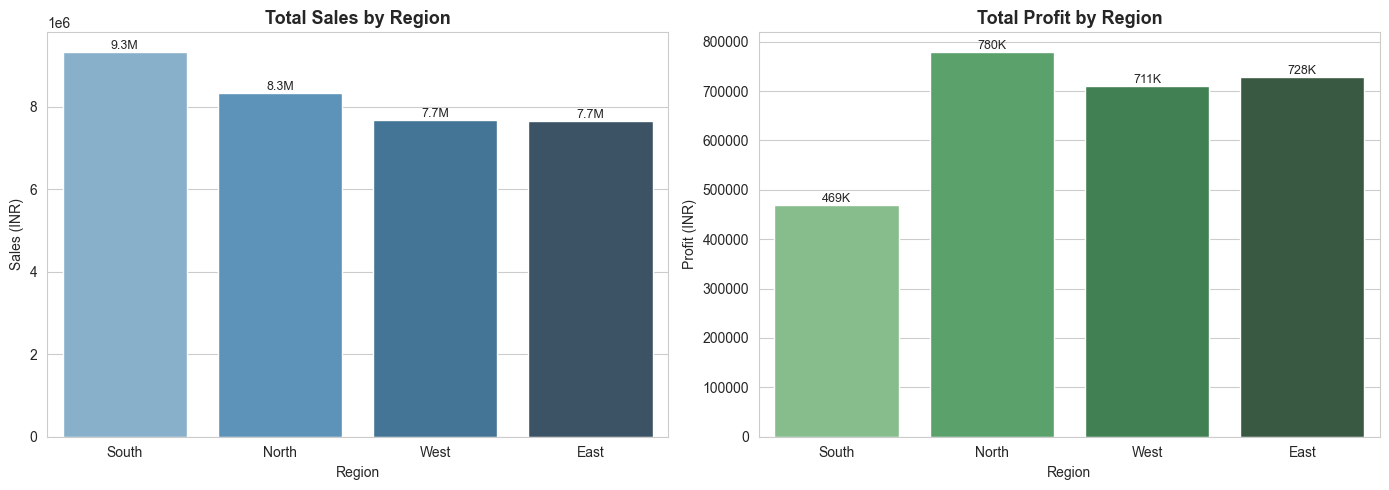

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=region_summary.reset_index(), x='Region', y='Total_Sales', ax=axes[0], palette='Blues_d', hue='Region', legend=False)
axes[0].set_title('Total Sales by Region')
axes[0].set_ylabel('Sales (INR)')
for i, v in enumerate(region_summary['Total_Sales']):
    axes[0].text(i, v, f'{v/1e6:.1f}M', ha='center', va='bottom', fontsize=9)

sns.barplot(data=region_summary.reset_index(), x='Region', y='Total_Profit', ax=axes[1], palette='Greens_d', hue='Region', legend=False)
axes[1].set_title('Total Profit by Region')
axes[1].set_ylabel('Profit (INR)')
for i, v in enumerate(region_summary['Total_Profit']):
    axes[1].text(i, v, f'{v/1e3:.0f}K', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


**Insight:** South leads on Sales (₹93.4L) but is *not* the most profitable region — its avg. profit margin (4.76%) is roughly **half** that of North, West, and East (~9% each). South also has the highest return rate (50%) and the lowest avg. rating (3.94★). Sales volume is masking a profitability and satisfaction problem in South.

### 2.1.1 Regional Deep-Dive Analysis >> South

In [9]:
''' South: Category Contribution '''


south_df = df[df['Region'] == 'South'].copy()

south_cat = south_df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Discount_pct=('Discount_pct','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

south_cat

,Category,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Discount_pct,Return_Rate_pct,Avg_Rating
1,Fashion,2834632,"56,692.64",47,2.00,29.13,51.06,4.07
0,Electronics,2384693,"47,704.76",35,2.00,28.80,45.71,3.91
2,Furniture,2122558,"296,115.56",36,12.12,28.50,50.00,3.76
3,Home Appliances,1993576,"68,703.25",29,3.43,29.90,55.17,3.97


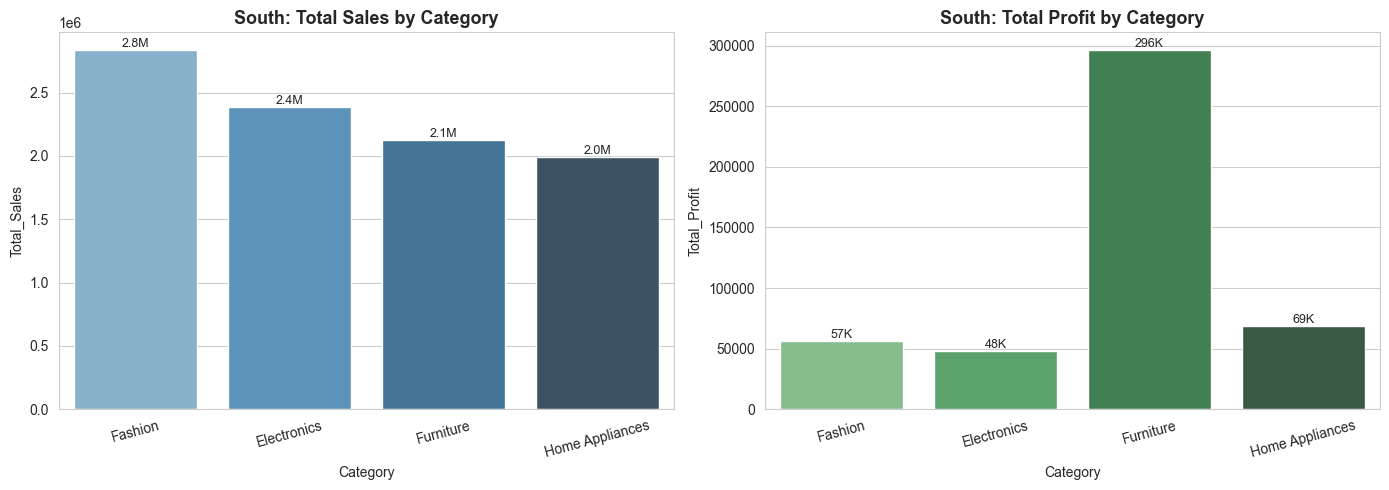

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Sales vs Profit by Category in South
sns.barplot(data=south_cat, x='Category', y='Total_Sales', palette='Blues_d', ax=axes[0], hue='Category', legend=False)
axes[0].set_title('South: Total Sales by Category')
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(south_cat['Total_Sales']):
    axes[0].text(i, v, f'{v/1e6:.1f}M', ha='center', va='bottom', fontsize=9)


sns.barplot(data=south_cat, x='Category', y='Total_Profit', palette='Greens_d', ax=axes[1], hue='Category', legend=False)
axes[1].set_title('South: Total Profit by Category')
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(south_cat['Total_Profit']):
    axes[1].text(i, v, f'{v/1e3:.0f}K', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [25]:
south_df.head()

,Order_ID,Order_Date,Region,Category,Sales,Discount_pct,Profit,Delivery_Days,Customer_Rating,Returned,Month,Month_Name,Quarter,Profit_Margin_pct,Returned_Flag,Discount_Bucket
1,NC10002,2025-08-23,South,Home Appliances,57370,33,"1,147.40",10,3.00,Yes,8,Aug,Q3,2.00,1,31-35%
5,NC10006,2025-06-06,South,Fashion,2410,34,48.20,6,4.50,No,6,Jun,Q2,2.00,0,31-35%
9,NC10010,2025-09-01,South,Fashion,106505,34,"2,130.10",9,3.40,Yes,9,Sep,Q3,2.00,1,31-35%
14,NC10015,2025-09-06,South,Electronics,77535,27,"1,550.70",2,4.80,No,9,Sep,Q3,2.00,0,21-30%
17,NC10018,2025-06-01,South,Electronics,57730,28,"1,154.60",5,4.80,No,6,Jun,Q2,2.00,0,21-30%


In [28]:
''' South: Month-on-Month Trend '''


south_monthly = south_df.groupby(['Month','Month_Name']).agg(
    Total_Orders=('Order_ID','nunique'),
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).sort_values('Month').reset_index()

south_monthly

,Month,Month_Name,Total_Orders,Sales,Profit,Avg_Margin,Avg_Discount,Return_Rate,Avg_Rating
0,1,Jan,7,332756,"19,154.94",5.85,26.71,57.14,4.23
1,2,Feb,12,793588,"47,402.63",6.01,29.08,41.67,3.62
2,3,Mar,10,553015,"20,934.76",3.64,27.50,30.00,4.11
3,4,Apr,12,956979,"24,541.07",2.63,28.92,41.67,4.01
4,5,May,12,685022,"49,266.41",6.79,30.58,75.00,3.80
5,6,Jun,11,580429,"11,998.37",2.05,31.27,72.73,3.80
6,7,Jul,17,917749,"47,813.12",4.50,28.53,52.94,3.89
7,8,Aug,15,1161356,"41,556.49",3.95,29.80,53.33,3.87
8,9,Sep,18,1301733,"60,588.68",4.24,28.78,33.33,3.99
9,10,Oct,14,871351,"54,664.02",5.93,29.21,50.00,3.94


**Insight:** South's discount stayed elevated all year (26.7%-31.3%, never dipping toward the 0-10% band other regions regularly reach) — confirming this is a standing pricing policy, not a seasonal promotion. Return rate, however, swings sharply month to month — spiking to 75% in May and 73% in June, well above South's own 50.3% annual average. That's a strong enough deviation from South's own baseline to flag as a specific mid-year operational lead (e.g. a logistics disruption or quality lapse) worth investigating beyond what this dataset alone can diagnose. (Note: monthly cuts here run to ~10-20 orders, so treat the exact spike size as directional, not precise.)

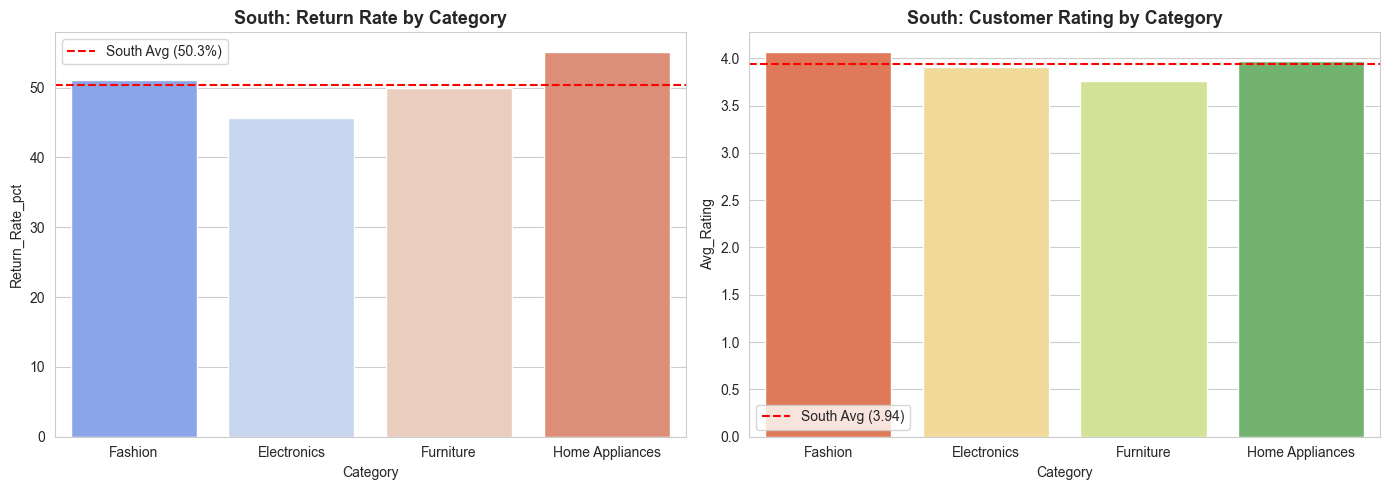

In [12]:
''' South: Returns & Ratings by Category '''


fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=south_cat, x='Category', y='Return_Rate_pct', palette='coolwarm', ax=axes[0], hue='Category', legend=False)
axes[0].set_title('South: Return Rate by Category')
axes[0].axhline(y=south_df['Returned_Flag'].mean()*100, 
                color='red', linestyle='--', label='South Avg (50.3%)')
axes[0].legend()


sns.barplot(data=south_cat, x='Category', y='Avg_Rating', palette='RdYlGn', ax=axes[1], hue='Category', legend=False)
axes[1].set_title('South: Customer Rating by Category')
axes[1].axhline(y=south_df['Customer_Rating'].mean(), 
                color='red', linestyle='--', label='South Avg (3.94)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight:** Fashion leads South's sales (₹28.3L, the single largest region-category combination in the entire dataset) but ranks near-last on profit (₹56.7K, 2.00% margin). Furniture — only third by sales in South — delivers by far the most South profit (₹2.96L, 12.12% margin), nearly 3x the top-selling category. South applies a near-identical ~28-30% average discount across every category regardless of that category's normal margin economics — this is a uniform regional pricing pattern, not a product-mix problem. Notably, Furniture — South's best-margin category — also carries South's worst customer rating (3.76★), lower even than the 2%-margin categories, suggesting a fulfillment quality issue specific to Furniture in South worth investigating separately from the discounting story.

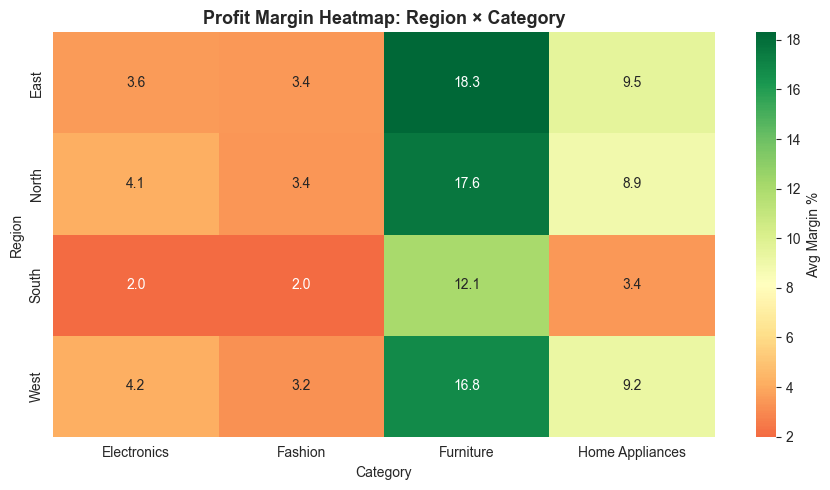

In [13]:
# ------------------------------------------------------------------
# 3.2 All Regions: Side-by-Side Category Performance
# ------------------------------------------------------------------

region_cat = df.groupby(['Region','Category']).agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index()

# Heatmap: Profit Margin % across Region x Category
pivot_margin = region_cat.pivot(index='Region', columns='Category', values='Avg_Margin')

plt.figure(figsize=(9,5))
sns.heatmap(pivot_margin, annot=True, fmt='.1f', cmap='RdYlGn', 
            center=8.15, cbar_kws={'label':'Avg Margin %'})
plt.title('Profit Margin Heatmap: Region × Category')
plt.tight_layout()
plt.show()

**Insight:** Furniture is the strongest category in every single region (12-18% margin), while Electronics and Fashion are structurally thin nearly everywhere (2-4%). South is the clear outlier on this heatmap — its Electronics and Fashion margins compress to almost exactly 2.0%. South's Furniture margin (12.12%) is also its strongest category, yet still runs ~30% below Furniture's performance in every other region (16.8-18.3%) — evidence this is a regional effect layered on top of the category effect, not explained by category alone.

### 2.1.2 Regional Deep-Dive Analysis >> West

In [14]:
''' West: Category Contribution '''


west_df = df[df['Region'] == 'West'].copy()

west_cat = west_df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Discount_pct=('Discount_pct','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

west_cat

,Category,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Discount_pct,Return_Rate_pct,Avg_Rating
2,Furniture,2194816,"388,973.80",42,16.81,17.52,21.43,4.79
0,Electronics,2176358,"100,931.19",38,4.22,16.18,15.79,4.82
3,Home Appliances,1777284,"165,705.69",28,9.21,15.64,14.29,4.84
1,Fashion,1533621,"55,618.02",30,3.22,14.93,16.67,4.84


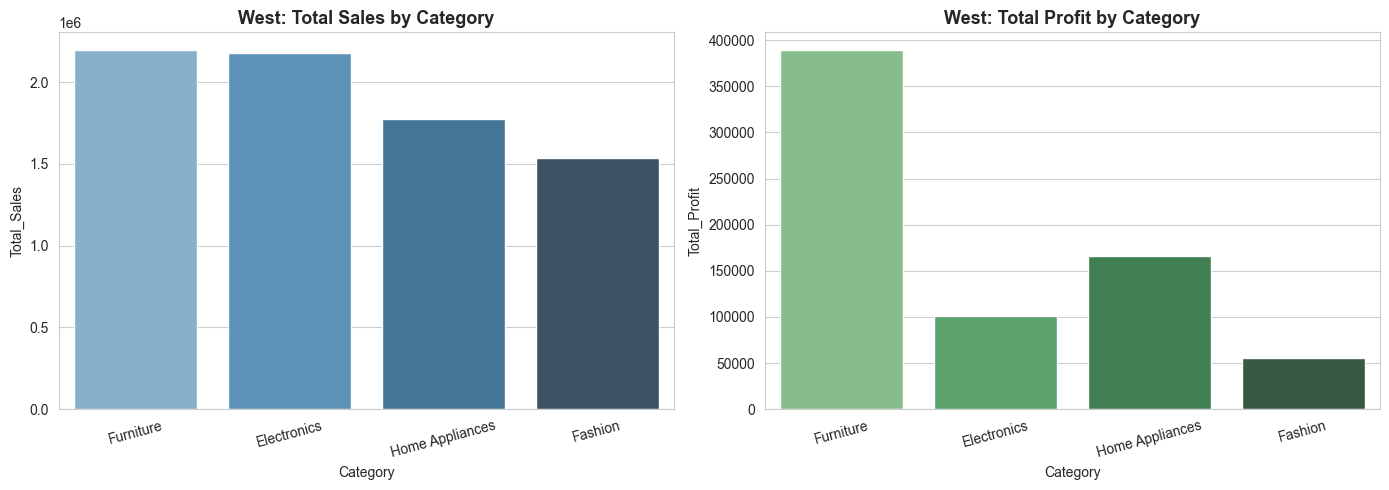

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Sales vs Profit by Category in South
sns.barplot(data=west_cat, x='Category', y='Total_Sales', palette='Blues_d', ax=axes[0], hue='Category', legend=False)
axes[0].set_title('West: Total Sales by Category')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=west_cat, x='Category', y='Total_Profit', palette='Greens_d', ax=axes[1], hue='Category', legend=False)
axes[1].set_title('West: Total Profit by Category')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [16]:
'''West: Month-on-Month Trend '''


west_monthly = west_df.groupby(['Month','Month_Name']).agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).sort_values('Month').reset_index()

west_monthly

,Month,Month_Name,Sales,Profit,Avg_Margin,Avg_Discount,Return_Rate,Avg_Rating
0,1,Jan,807766,"56,783.81",6.24,14.71,14.29,4.80
1,2,Feb,419986,"35,259.66",7.69,16.50,25.00,4.75
2,3,Mar,830037,"51,075.82",6.44,19.25,8.33,4.77
3,4,Apr,569806,"37,324.99",7.40,18.22,33.33,4.73
4,5,May,326817,"26,819.85",9.44,11.14,14.29,4.97
5,6,Jun,779136,"55,817.18",7.55,17.08,23.08,4.80
6,7,Jul,981575,"106,209.90",11.25,18.84,26.32,4.81
7,8,Aug,755353,"87,247.93",9.41,13.06,11.76,4.86
8,9,Sep,894954,"108,796.50",12.14,15.43,21.43,4.91
9,10,Oct,188229,"13,880.93",6.60,21.43,28.57,4.89


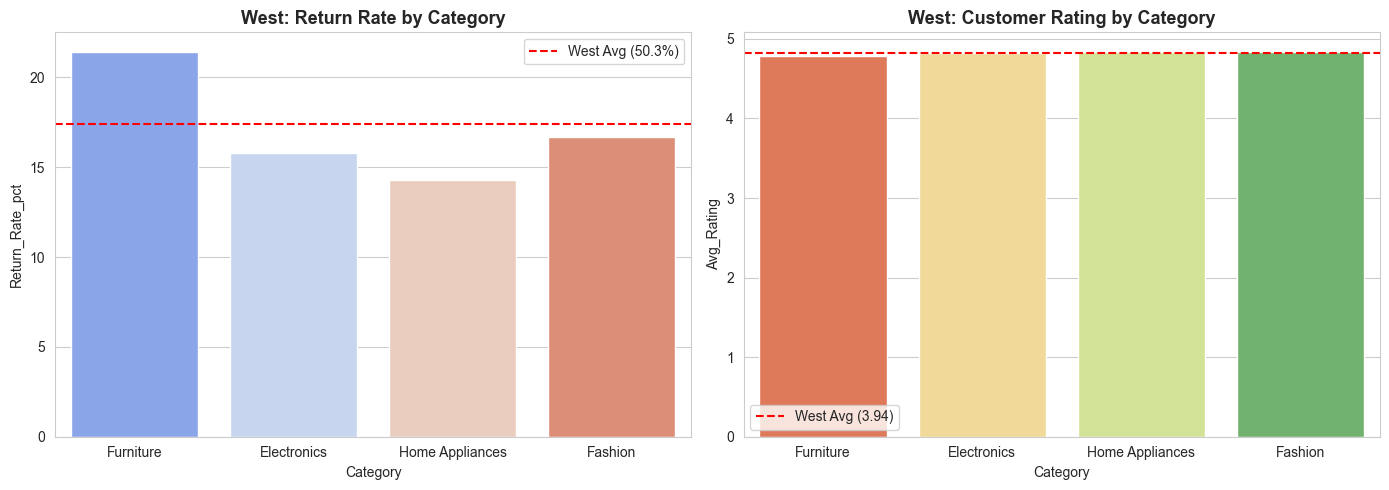

In [17]:
# ------------------------------------------------------------------
# West: Returns & Ratings by Category
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=west_cat, x='Category', y='Return_Rate_pct', palette='coolwarm', ax=axes[0], hue='Category', legend=False)
axes[0].set_title('West: Return Rate by Category')
axes[0].axhline(y=west_df['Returned_Flag'].mean()*100, 
                color='red', linestyle='--', label='West Avg (50.3%)')
axes[0].legend()

sns.barplot(data=west_cat, x='Category', y='Avg_Rating', palette='RdYlGn', ax=axes[1], hue='Category', legend=False)
axes[1].set_title('West: Customer Rating by Category')
axes[1].axhline(y=west_df['Customer_Rating'].mean(), 
                color='red', linestyle='--', label='West Avg (3.94)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight:** Furniture again leads on both sales (₹21.9L) and margin (16.81%) in West — the only clean "double win" alongside North's Furniture. West's average discount is the lowest of any region in every single category (11-21%, vs. South's 28-30% floor), and its return rates follow suit — the lowest of any region in every category (14-21%). Ratings hold at a uniformly high 4.79-4.84★ across all four categories, and two months (October, November) recorded a 0% return rate. West is effectively the closest thing in this dataset to a control group showing what NovaCart's numbers look like without heavy discounting.

### 2.1.3 Regional Deep-Dive Analysis >> North & East

In [18]:
''' North: Category Contribution '''

north_df = df[df['Region'] == 'North'].copy()

north_cat = north_df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Discount_pct=('Discount_pct','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

north_cat

,Category,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Discount_pct,Return_Rate_pct,Avg_Rating
2,Furniture,2484881,"446,466.33",39,17.59,18.23,23.08,4.14
1,Fashion,1959143,"72,170.82",32,3.36,16.78,28.12,4.15
0,Electronics,1958144,"82,556.55",32,4.11,17.31,25.00,4.22
3,Home Appliances,1923358,"178,829.64",35,8.92,15.66,22.86,4.17


In [19]:
''' East: Category Contribution '''

east_df = df[df['Region'] == 'East'].copy()

east_cat = east_df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Discount_pct=('Discount_pct','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

east_cat


,Category,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Discount_pct,Return_Rate_pct,Avg_Rating
0,Electronics,2044249,"85,890.41",35,3.57,17.94,31.43,4.34
2,Furniture,2016001,"384,985.77",33,18.30,16.70,30.30,4.09
1,Fashion,1814159,"67,041.91",29,3.41,17.90,24.14,4.49
3,Home Appliances,1779384,"189,985.46",30,9.54,14.30,20.00,4.24


**Insight:** North repeats West's pattern — Furniture leads both sales (₹24.8L, North's largest category) and margin (17.59%). East is the one region where Furniture does not lead sales — Electronics does (₹20.4L) — even though Furniture still leads on margin (18.30%, the single highest margin of any region-category cell in the whole dataset). East's Electronics also carries the highest return rate of any category within East (31.43%) — East's top-selling category is also its most return-prone.

### 2.2 Performance by Category

In [20]:
category_summary = df.groupby('Category').agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Avg_Rating=('Customer_Rating','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100)
).round(2).reset_index().sort_values('Total_Sales', ascending=False)

category_summary


,Category,Total_Sales,Total_Profit,Orders,Avg_Margin_pct,Avg_Rating,Return_Rate_pct
2,Furniture,8818256,"1,516,541.46",150,16.22,4.22,30.67
0,Electronics,8563444,"317,082.91",140,3.48,4.34,29.29
1,Fashion,8141555,"251,523.39",138,2.88,4.34,32.61
3,Home Appliances,7473602,"603,224.04",122,7.83,4.29,27.87


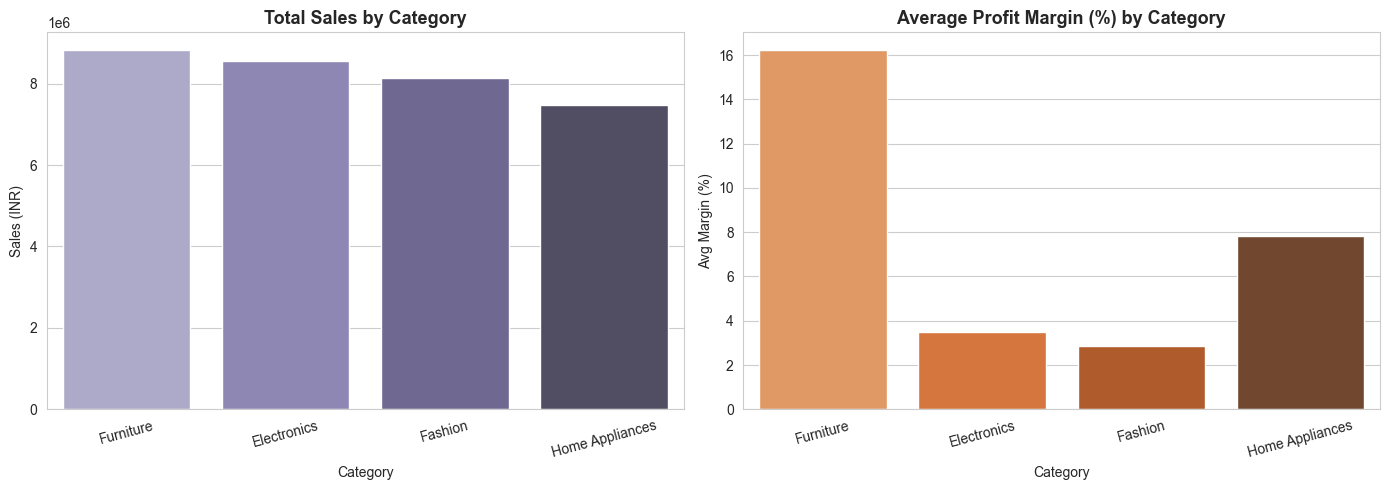

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=category_summary.reset_index(), x='Category', y='Total_Sales', ax=axes[0], palette='Purples_d', hue='Category', legend=False)
axes[0].set_title('Total Sales by Category')
axes[0].set_ylabel('Sales (INR)')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=category_summary.reset_index(), x='Category', y='Avg_Margin_pct', ax=axes[1], palette='Oranges_d', hue='Category', legend=False)
axes[1].set_title('Average Profit Margin (%) by Category')
axes[1].set_ylabel('Avg Margin (%)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


**Insight:** Furniture has mid-pack sales but by far the **highest profit margin (16.2%)** and highest total profit (₹15.2L) — it's the most efficient category. Electronics and Fashion generate comparable sales to Furniture but convert it into far less profit (margins of 3.5% and 2.9%) — these categories are high-revenue, low-yield.

### 2.2.1 Category Deep-Dive Analysis >> Electronics & Fashion

In [23]:
''' 4.1 Electronics: Regional & Discount Breakdown '''


electric = df[df['Category']=='Electronics'].copy()

elec_region = electric.groupby('Region').agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Sales', ascending=False)

elec_region

,Region,Sales,Profit,Orders,Avg_Margin,Avg_Discount,Return_Rate,Avg_Rating
2,South,2384693,"47,704.76",35,2.00,28.80,45.71,3.91
3,West,2176358,"100,931.19",38,4.22,16.18,15.79,4.82
0,East,2044249,"85,890.41",35,3.57,17.94,31.43,4.34
1,North,1958144,"82,556.55",32,4.11,17.31,25.00,4.22


In [24]:
''' 4.2 Fashion: Regional & Discount Breakdown '''


fashion = df[df['Category']=='Fashion'].copy()

fash_region = fashion.groupby('Region').agg(
    Sales=('Sales','sum'),
    Profit=('Profit','sum'),
    Orders=('Order_ID','count'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean')
).round(2).reset_index().sort_values('Sales', ascending=False)

fash_region

,Region,Sales,Profit,Orders,Avg_Margin,Avg_Discount,Return_Rate,Avg_Rating
2,South,2834632,"56,692.64",47,2.00,29.13,51.06,4.07
1,North,1959143,"72,170.82",32,3.36,16.78,28.12,4.15
0,East,1814159,"67,041.91",29,3.41,17.90,24.14,4.49
3,West,1533621,"55,618.02",30,3.22,14.93,16.67,4.84


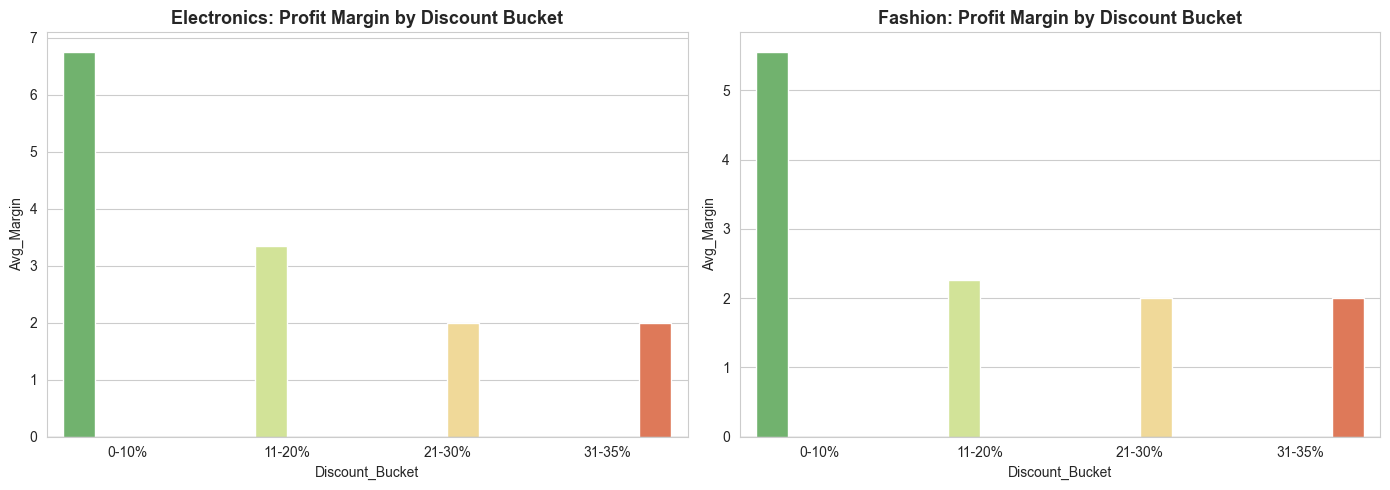

In [24]:
''' Electronics & Fashion: Discount Bucket Analysis '''


low_margin_cats = df[df['Category'].isin(['Electronics','Fashion'])]

bucket_analysis = low_margin_cats.groupby(['Category','Discount_Bucket']).agg(
    Orders=('Order_ID','count'),
    Avg_Sales=('Sales','mean'),
    Avg_Profit=('Profit','mean'),
    Avg_Margin=('Profit_Margin_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100)
).round(2).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14,5))

for ax, cat in zip(axes, ['Electronics','Fashion']):
    sub = bucket_analysis[bucket_analysis['Category']==cat]
    sns.barplot(data=sub, x='Discount_Bucket', y='Avg_Margin', ax=ax, palette='RdYlGn_r', hue='Discount_Bucket', legend=False)
    ax.set_title(f'{cat}: Profit Margin by Discount Bucket')
    ax.axhline(y=0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

**Insight:** South and West sell nearly the same amount of Electronics by revenue (₹23.8L vs ₹21.8L), yet South's profit (₹47.7K) is under half of West's (₹100.9K) — almost entirely explained by South's ~29% average discount vs. West's ~16%. The Fashion comparison is sharper still: South's Fashion sales (₹28.3L) are the largest region-category cell in the dataset, yet its profit (₹56.7K) barely edges out West's Fashion profit (₹55.6K) despite West selling 46% less Fashion by revenue. On the discount-bucket chart: both categories start with a real (if modest) margin at low discount — 6.76% for Electronics, 5.56% for Fashion — and collapse toward a near-zero floor by the 21-30% band. In practical terms, discounting beyond ~20% is operating at essentially no incremental margin for these two categories specifically.

### 2.3 Region × Category Sales Breakdown

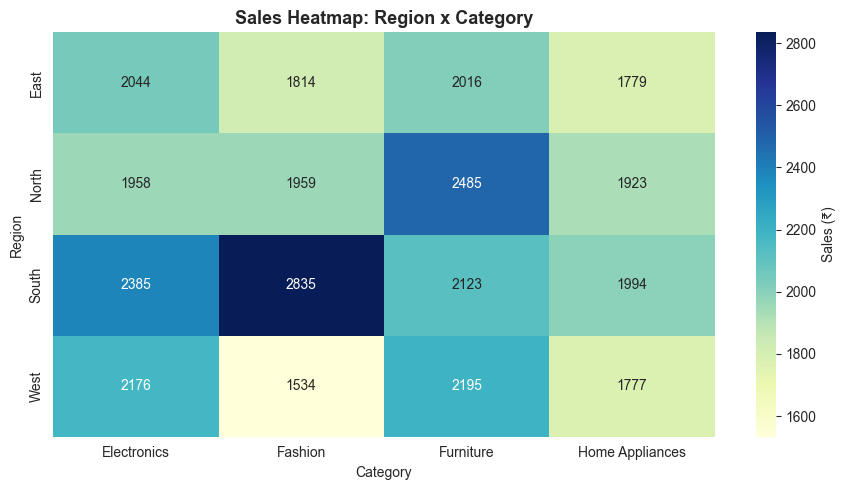

In [25]:
pivot_sales = df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum')

plt.figure(figsize=(9,5))
sns.heatmap(pivot_sales/1000, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label':'Sales (₹)'})
plt.title('Sales Heatmap: Region x Category')
plt.tight_layout()
plt.show()


**Insight:** South Fashion (₹28.3L) is the single largest region-category cell in the dataset, followed by North Furniture (₹24.8L). Cross-referencing this with the margin heatmap earlier makes the core tension visible at a glance: NovaCart's biggest revenue cell (South Fashion) is one of its worst margin cells, while a mid-sized cell (North Furniture) is among the best. Revenue concentration and profit concentration are pointing in different directions.

### 2.4 Monthly Sales & Profit Trend

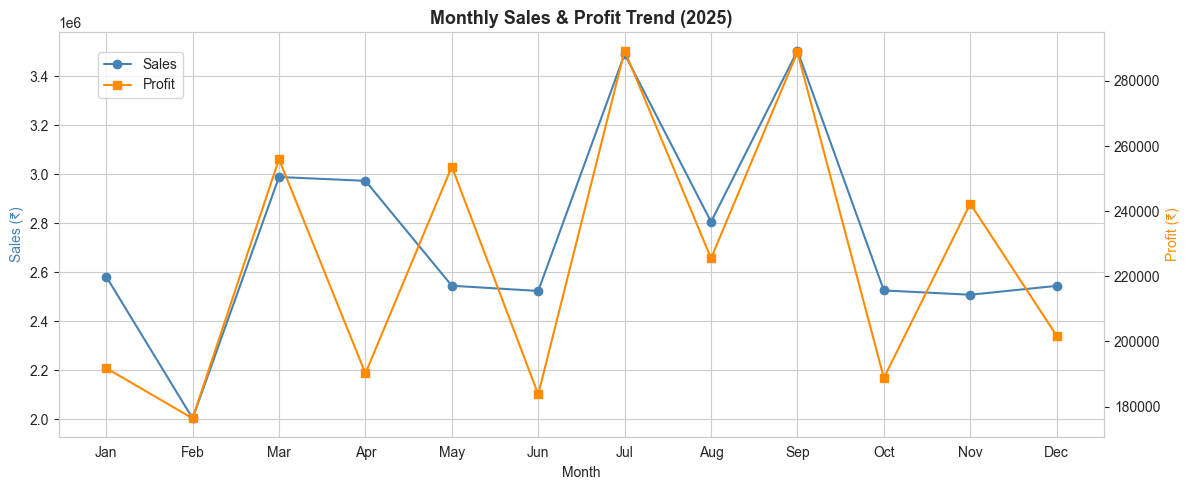

In [26]:
monthly = df.groupby(['Month','Month_Name']).agg(Sales=('Sales','sum'), Profit=('Profit','sum')).reset_index().sort_values('Month')

fig, ax1 = plt.subplots(figsize=(12,5))
ax2 = ax1.twinx()
ax2.grid(False)   # turn off gridlines for the right y-axis, to avoid overlapping gridlines

ax1.plot(monthly['Month_Name'], monthly['Sales'], marker='o', color='steelblue', label='Sales')
ax2.plot(monthly['Month_Name'], monthly['Profit'], marker='s', color='darkorange', label='Profit')

ax1.set_ylabel('Sales (₹)', color='steelblue')
ax2.set_ylabel('Profit (₹)', color='darkorange')
ax1.set_title('Monthly Sales & Profit Trend (2025)')
ax1.set_xlabel('Month')

fig.legend(loc='upper left', bbox_to_anchor=(0.08,0.9))
plt.tight_layout()
plt.show()

**Insight:** Sales peak in **July and September** (₹34.9L and ₹35.0L) — worth checking against any promotional calendar/seasonal demand (e.g. festive season run-up). February is the low point. Profit doesn't track sales month-to-month as tightly, reinforcing that revenue timing and profitability are driven by different factors (likely discounting behavior, category mix).

### 2.5 Discount Impact on Margin, Sales & Returns

In [27]:
discount_summary = df.groupby('Discount_Bucket', observed=True).agg(
    Avg_Sales=('Sales','mean'),
    Avg_Margin_pct=('Profit_Margin_pct','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Orders=('Order_ID','count')
).reset_index().round(2)

discount_summary

,Discount_Bucket,Avg_Sales,Avg_Margin_pct,Return_Rate_pct,Orders
0,0-10%,"57,381.92",12.15,7.46,134
1,11-20%,"56,608.13",8.77,17.21,122
2,21-30%,"62,118.75",6.20,30.53,190
3,31-35%,"63,451.21",3.82,74.04,104


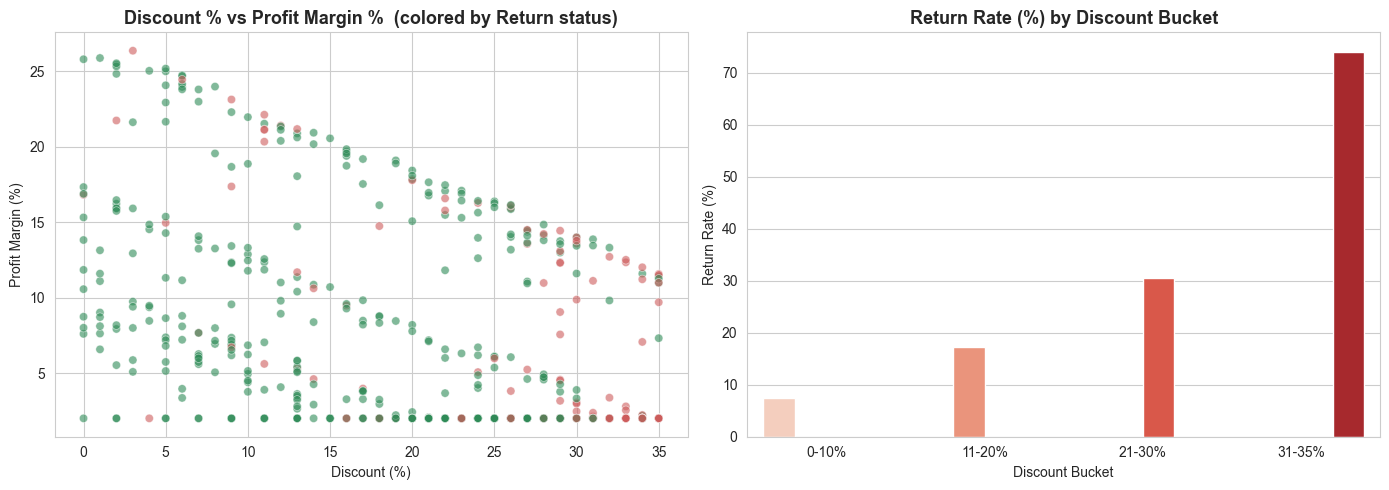

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.scatterplot(data=df, x='Discount_pct', y='Profit_Margin_pct', hue='Returned', alpha=0.6, ax=axes[0], palette={'No':'seagreen','Yes':'indianred'}, legend=False)
axes[0].set_title('Discount % vs Profit Margin %  (colored by Return status)')
axes[0].set_xlabel('Discount (%)')
axes[0].set_ylabel('Profit Margin (%)')

sns.barplot(data=discount_summary.reset_index(), x='Discount_Bucket', y='Return_Rate_pct', ax=axes[1], palette='Reds', hue='Discount_Bucket', legend=False)
axes[1].set_title('Return Rate (%) by Discount Bucket')
axes[1].set_ylabel('Return Rate (%)')
axes[1].set_xlabel('Discount Bucket')

plt.tight_layout()
plt.show()

**Key Insight (discount vs. revenue/profit — flagged explicitly in the brief):** Higher discounting does **not** meaningfully grow order value (avg. sales per order is roughly flat, ₹57K→₹63K, across discount tiers) but it **steadily destroys margin** — average margin drops from **12.2% (0–10% discount)** to **3.8% (31–35% discount)**. Worse, the **return rate climbs from 7% to 74%** across the same tiers. NovaCart is discounting away its profit *and* generating more returns for it — discounting is not paying for itself in this dataset.

### 2.6 Customer Ratings & Delivery Performance

In [29]:
delivery_summary = df.groupby('Delivery_Days').agg(
    Avg_Rating=('Customer_Rating','mean'),
    Return_Rate_pct=('Returned_Flag', lambda x: x.mean()*100),
    Orders=('Order_ID','count')
).reset_index().round(2)

delivery_summary

,Delivery_Days,Avg_Rating,Return_Rate_pct,Orders
0,2,4.69,28.05,82
1,3,4.72,21.43,84
2,4,4.70,23.81,84
3,5,4.72,19.05,84
4,6,4.57,18.18,44
5,7,3.46,45.83,48
6,8,3.51,28.12,32
7,9,3.38,54.17,48
8,10,3.41,54.55,44


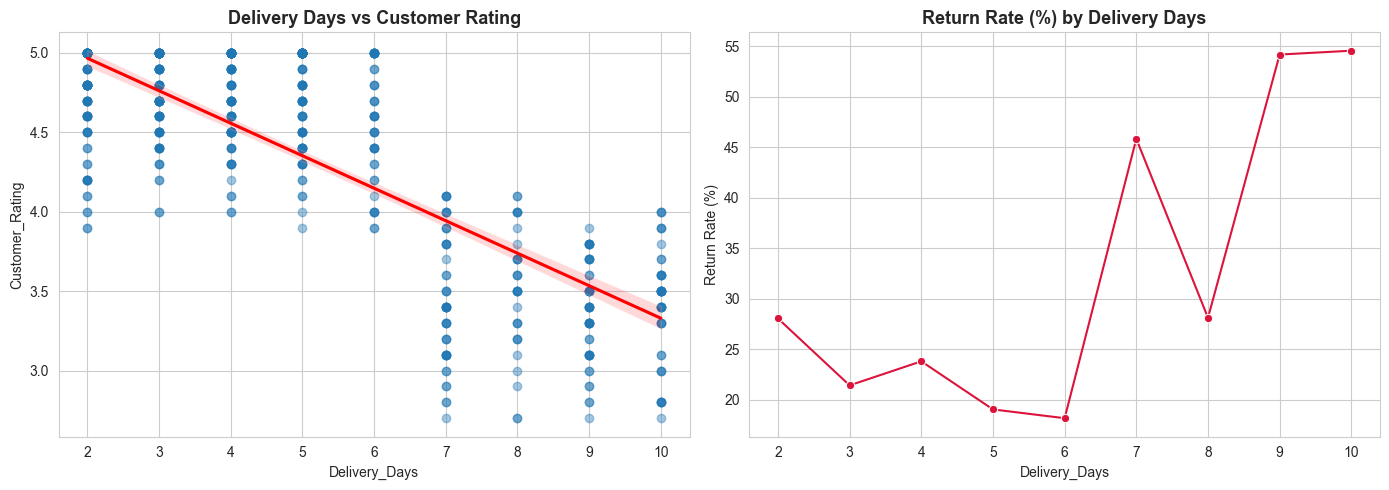

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.regplot(data=df, x='Delivery_Days', y='Customer_Rating', ax=axes[0], scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
axes[0].set_title('Delivery Days vs Customer Rating')

sns.lineplot(data=delivery_summary.reset_index(), x='Delivery_Days', y='Return_Rate_pct', marker='o', ax=axes[1], color='crimson')
axes[1].set_title('Return Rate (%) by Delivery Days')
axes[1].set_ylabel('Return Rate (%)')

plt.tight_layout()
plt.show()


In [31]:
print("Correlation, Delivery_Days vs Customer_Rating:", round(df['Delivery_Days'].corr(df['Customer_Rating']),2))
print("Correlation, Delivery_Days vs Returned_Flag:", round(df['Delivery_Days'].corr(df['Returned_Flag']),2))


Correlation, Delivery_Days vs Customer_Rating: -0.78
Correlation, Delivery_Days vs Returned_Flag: 0.21


**Insight:** Delivery speed is one of the strongest drivers in the dataset. Ratings hold steady around **4.6–4.7★** for deliveries up to 6 days, then fall off a cliff to **~3.4–3.5★** for 7+ day deliveries (correlation **-0.78**, the strongest relationship in the data). Return rate roughly **doubles** past the 6-day mark (from ~20% to 45–55%). There's a clear delivery-time threshold effect around 6 days.

### 2.7 Returned vs. Not-Returned Orders — Profile Comparison

In [32]:
returned_compare = df.groupby('Returned').agg(
    Avg_Rating=('Customer_Rating','mean'),
    Avg_Discount_pct=('Discount_pct','mean'),
    Avg_Delivery_Days=('Delivery_Days','mean'),
    Avg_Margin_pct=('Profit_Margin_pct','mean')
).reset_index().round(2)

returned_compare

,Returned,Avg_Rating,Avg_Discount_pct,Avg_Delivery_Days,Avg_Margin_pct
0,No,4.47,16.80,4.93,8.54
1,Yes,3.90,27.31,6.07,5.99


**Insight:** Returned orders had, on average, **higher discounts (27.3% vs 16.8%)**, **slower delivery (6.1 vs 4.9 days)**, and **lower ratings (3.9★ vs 4.5★)** than kept orders. Discount depth and delivery delay both associate with returns — this triangulates with the two findings above rather than standing alone.

### >> Cross-Cutting & Additional Insights

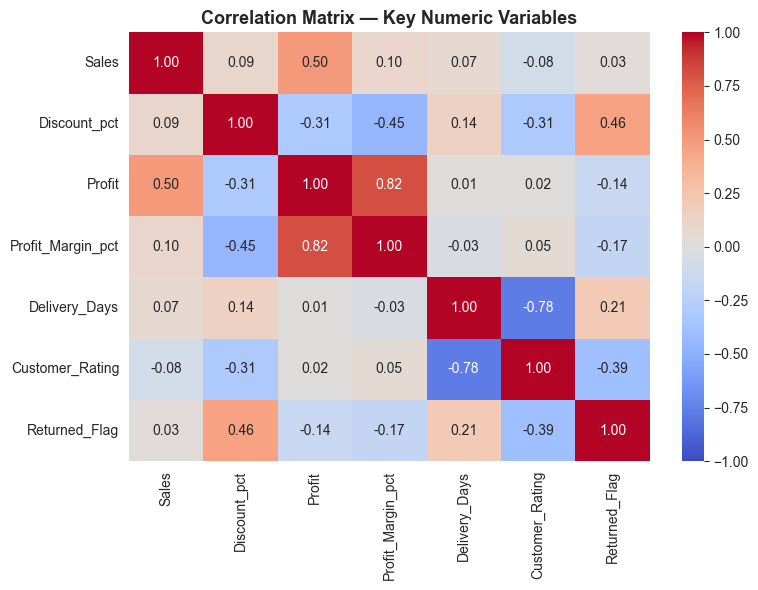

In [35]:
# ------------------------------------------------------------------
# Correlation Matrix of Numeric Variables
# ------------------------------------------------------------------

corr_cols = ['Sales','Discount_pct','Profit','Profit_Margin_pct','Delivery_Days','Customer_Rating','Returned_Flag']
corr = df[corr_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix — Key Numeric Variables')
plt.tight_layout()
plt.show()


**Insight:** Profit correlates most strongly with Sales (r = 0.50) and, by construction, with Profit_Margin_% (r = 0.82). Discount's damage shows up primarily in margin (r = -0.45) rather than wiping out absolute profit outright (r = -0.31 with Profit) — a larger discounted order can still clear a smaller but positive profit. Customer_Rating correlates negatively with both Discount_pct (r = -0.31) and Delivery_Days (r = -0.78) — delivery speed is a substantially stronger lever on satisfaction than discount depth is.

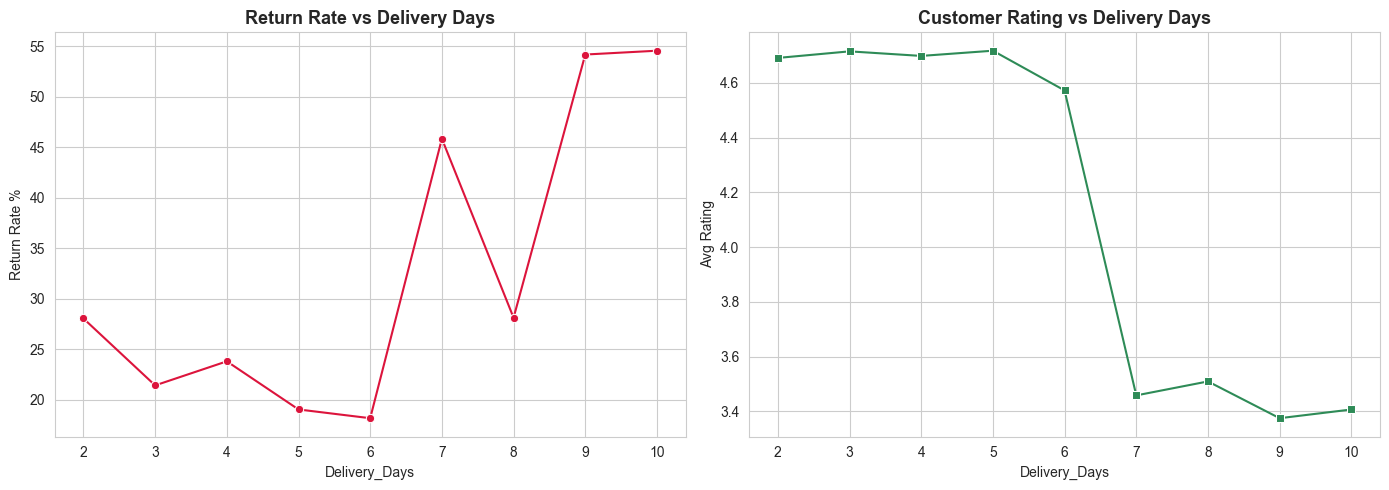

In [36]:
# ------------------------------------------------------------------
# Delivery Days Impact
# ------------------------------------------------------------------

delivery_impact = df.groupby('Delivery_Days').agg(
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean'),
    Order_Count=('Order_ID','count')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.lineplot(data=delivery_impact, x='Delivery_Days', y='Return_Rate', 
             marker='o', color='crimson', ax=axes[0])
axes[0].set_title('Return Rate vs Delivery Days')
axes[0].set_ylabel('Return Rate %')

sns.lineplot(data=delivery_impact, x='Delivery_Days', y='Avg_Rating', 
             marker='s', color='seagreen', ax=axes[1])
axes[1].set_title('Customer Rating vs Delivery Days')
axes[1].set_ylabel('Avg Rating')

plt.tight_layout()
plt.show()

#### High-Value vs Low-Value Order Profitability

C:\Users\allex\AppData\Local\Temp\ipykernel_6120\2083722105.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Avg_Margin', palette='viridis', ax=axes[0,0])
C:\Users\allex\AppData\Local\Temp\ipykernel_6120\2083722105.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Avg_Discount', palette='magma', ax=axes[0,1])
C:\Users\allex\AppData\Local\Temp\ipykernel_6120\2083722105.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=value_analysis,

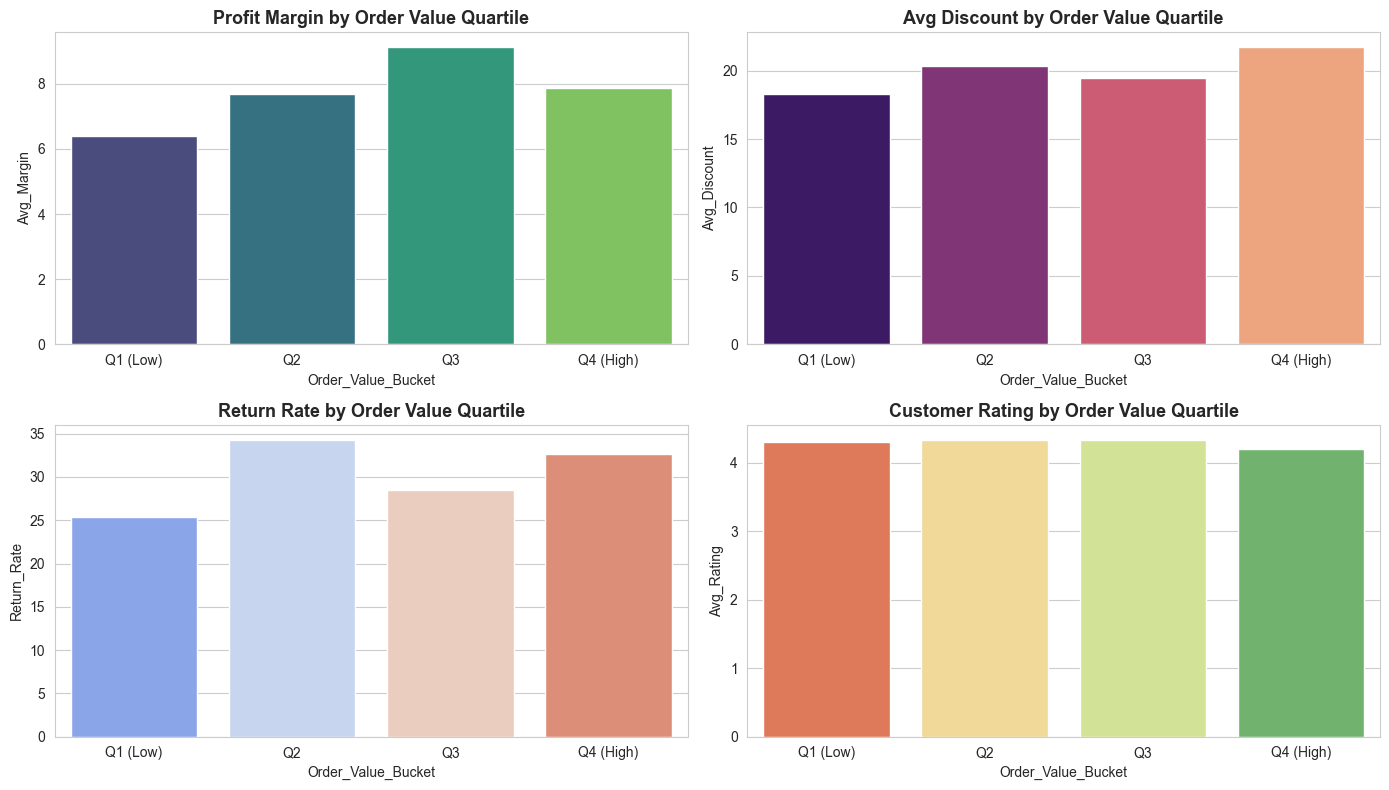

In [39]:
# ------------------------------------------------------------------
# Order Value Segmentation
# ------------------------------------------------------------------

df['Order_Value_Bucket'] = pd.qcut(df['Sales'], q=4, 
                                   labels=['Q1 (Low)','Q2','Q3','Q4 (High)'])

value_analysis = df.groupby('Order_Value_Bucket').agg(
    Avg_Margin=('Profit_Margin_pct','mean'),
    Avg_Discount=('Discount_pct','mean'),
    Return_Rate=('Returned_Flag', lambda x: x.mean()*100),
    Avg_Rating=('Customer_Rating','mean'),
    Order_Count=('Order_ID','count')
).round(2).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(14,8))

sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Avg_Margin', palette='viridis', ax=axes[0,0])
axes[0,0].set_title('Profit Margin by Order Value Quartile')

sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Avg_Discount', palette='magma', ax=axes[0,1])
axes[0,1].set_title('Avg Discount by Order Value Quartile')

sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Return_Rate', palette='coolwarm', ax=axes[1,0])
axes[1,0].set_title('Return Rate by Order Value Quartile')

sns.barplot(data=value_analysis, x='Order_Value_Bucket', y='Avg_Rating', palette='RdYlGn', ax=axes[1,1])
axes[1,1].set_title('Customer Rating by Order Value Quartile')

plt.tight_layout()
plt.show()

**Insight — hypothesis tested and ruled out:** There's no clean monotonic relationship between order size and margin, return rate, or rating. Q3 (mid-high value) actually has the best margin (9.13%) and a below-average return rate (~30%), while Q4 (the highest-value orders) isn't the best performer on any metric (7.87% margin, 32.61% return). This rules out "basket size" as an independent driver of the margin/return pattern seen elsewhere in this analysis — discount depth, category, and region are doing the work, not order size. Worth stating explicitly since it's a natural alternative hypothesis a stakeholder might raise.

#### Discount vs Profit Margin — The Smoking Gun

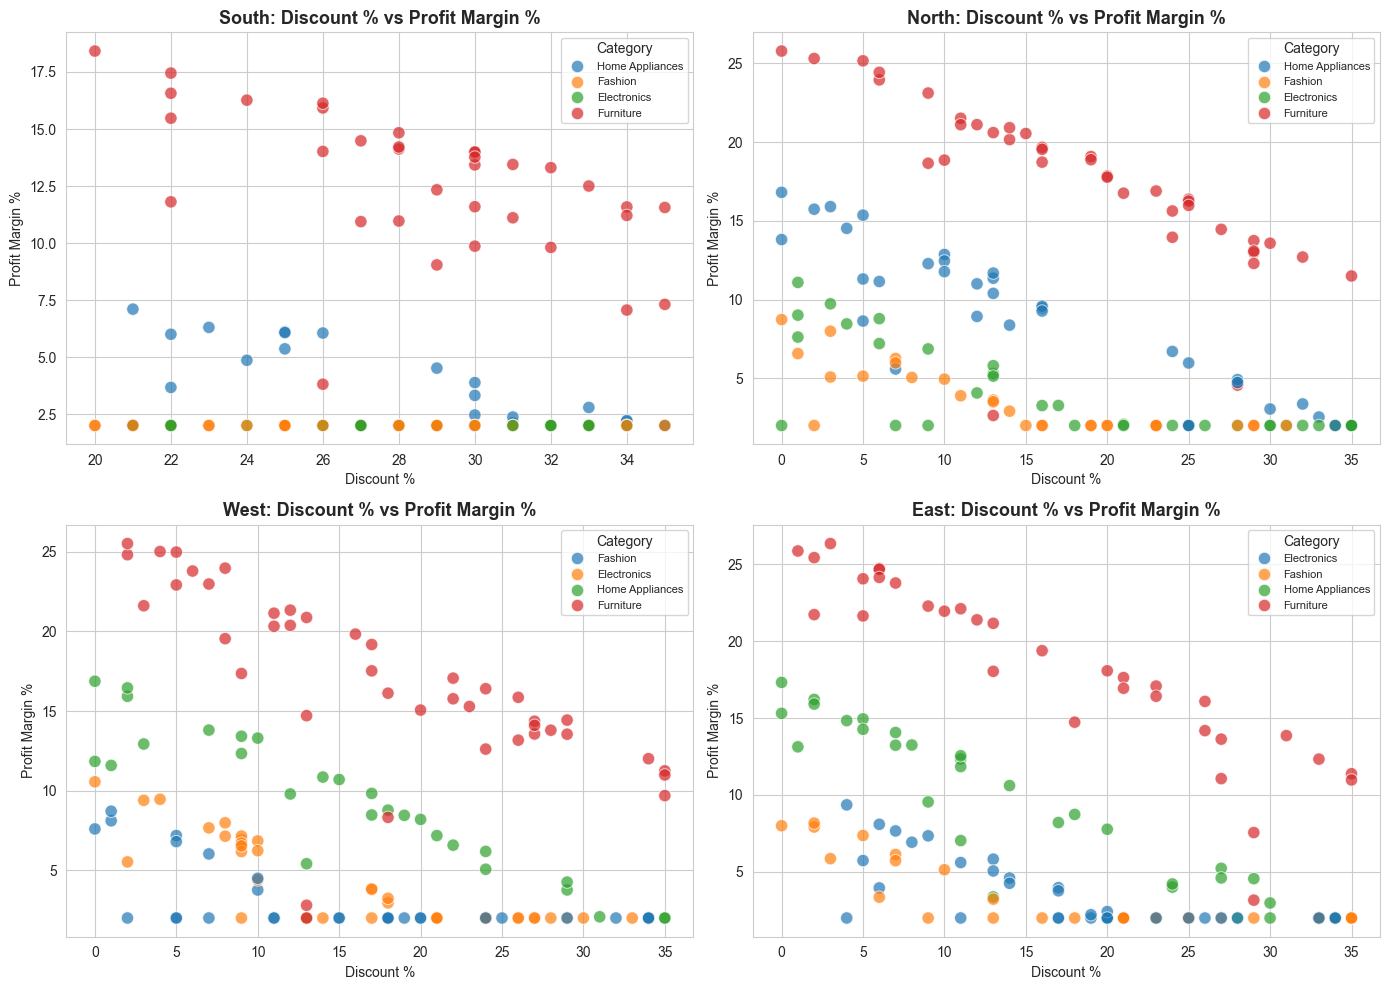

In [44]:
# ------------------------------------------------------------------
# Scatter: Discount % vs Profit Margin % (colored by Region)
# ------------------------------------------------------------------

regions = ['South', 'North', 'West', 'East']
fig, axes = plt.subplots(2, 2, figsize=(14,10))  # 2x2 grid


for ax, region in zip(axes.flatten(), regions):
    sns.scatterplot(
        data=df[df['Region'] == region],
        x='Discount_pct', y='Profit_Margin_pct',
        hue='Category', alpha=0.7, s=80, ax=ax
    )
    # ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'{region}: Discount % vs Profit Margin %')
    ax.set_xlabel('Discount %')
    ax.set_ylabel('Profit Margin %')
    ax.legend(title='Category', fontsize=8)

plt.tight_layout()
plt.show()

**Insight:** In every region, Furniture (the consistently highest-sitting cluster in each panel) retains a double-digit margin cushion at discount levels where Electronics, Fashion, and Home Appliances have already flattened toward the near-zero floor. South's panel is visibly shifted right — its points rarely appear below ~20% discount at all — while North, West, and East each show a full spread from 0% to 35%. This is the clearest visual confirmation that South's discount floor is a standing regional pattern, not an occasional promotion.

#### A Data Quality Note 

In [32]:
floor_mask = df['Profit_Margin_pct'].round(2) == 2.00
print("Orders at 2% floor:", floor_mask.sum(), "of", len(df), f"({floor_mask.mean()*100:.1f}%)")
print(df[floor_mask].groupby(['Region','Category']).size())

south_floor = df[(df['Region']=='South')]['Profit_Margin_pct'].round(2).eq(2.00).mean()
print(f"\nShare of South orders at floor: {south_floor*100:.1f}%")

floor_by_bucket = df.groupby('Discount_Bucket', observed=True).apply(
    lambda g: (g['Profit_Margin_pct'].round(2)==2.00).mean()*100
)
print(floor_by_bucket.round(1))

Orders at 2% floor: 218 of 550 (39.6%)
Region  Category       
East    Electronics        19
        Fashion            19
        Home Appliances     3
North   Electronics        17
        Fashion            19
        Home Appliances     4
South   Electronics        34
        Fashion            47
        Furniture           2
        Home Appliances    10
West    Electronics        19
        Fashion            22
        Furniture           1
        Home Appliances     2
dtype: int64

Share of South orders at floor: 63.3%
Discount_Bucket
0-10%     8.20
11-20%   28.70
21-30%   51.10
31-35%   72.10
dtype: float64


### Data quality note

 **A hidden 2% margin floor:** 218 of 550 orders (39.6%) sit at almost exactly a 2.00% profit margin — a suspiciously precise, repeated value for what should be a continuous number. It concentrates heavily in Electronics/Fashion (203 of 218 = 93%) and in South (93 of 218 = 43%, meaning 63.3% of all South orders hit this exact floor). The floor-hit rate rises predictably with discount band: 8.2% (0-10%) → 28.7% (11-20%) → 51.1% (21-30%) → 72.1% (31-35%). This pattern is far more consistent with a rule embedded in how the dataset was generated (e.g. Profit = max(formula, 2% x Sales)) than an organic business floor, and **is reported here as a data-quality observation rather than a business finding** — the direction of the discount-margin relationship is still trustworthy, but the literal "2%" figure should be verified against real data before being used in a pricing decision.

---
## Phase 4: Insight Generation & Recommendations

### Top / Bottom Performers

| Cut | Best | Worst |
|---|---|---|
| **Region — Sales** | South (₹93.4L) | West (₹76.8L) |
| **Region — Profit Margin** | North (8.97%) | South (4.76%) |
| **Category — Profit Margin** | Furniture (16.22%) | Fashion (2.88%) |
| **Category — Sales** | Furniture (₹88.2L) | Home Appliances (₹74.7L) |

### Key Insights Summary

1. **South is a volume trap.** Highest sales, but lowest margin (4.76% vs ~9% elsewhere), highest return rate (50%), and lowest customer rating (3.94★) — sales volume is masking a profitability and satisfaction problem specific to this region.
2. **Discounting isn't earning its keep.** Deeper discounts don't meaningfully raise average order value, but they cut margin by more than two-thirds (12.2% → 3.8%) and correlate with a 10x jump in return rate (7% → 74%) at the highest discount tier.
3. **Furniture is the profitability engine; Fashion and Electronics are volume without yield.** Furniture converts sales into profit ~5x more efficiently than Fashion.
4. **Delivery speed is the single strongest lever on customer experience.** Ratings and returns both break sharply once delivery exceeds ~6 days (rating corr. -0.78).
5. **Returns cluster around a specific profile** — heavier discounts + slower delivery + lower ratings — rather than being random/evenly distributed.

### Recommendations

1. **Cap or tier discounts by category, prioritizing Furniture-style margin protection.** Recommend capping promotional discounts at ~20% for Fashion/Electronics where margin is already thin, since the data shows deeper discounts don't grow order value.
2. **Investigate South region's return and satisfaction issue directly** (e.g. logistics partner, product mix, or local delivery capacity) — it's dragging down an otherwise strong sales region.
3. **Set a delivery SLA target of ≤6 days** where operationally feasible; this is the clearest threshold in the data for both rating and return-rate improvement.
4. **Shift marketing/inventory push toward Furniture and Home Appliances**, which deliver better margins per rupee of sales than Electronics/Fashion, without a corresponding hit to satisfaction.
5. **Add return-reason tracking** (not present in this dataset) — we can see returns correlate with discount depth and delivery delay, but not *why*, which limits how targeted a fix can be.
